In [14]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten
from tensorflow.keras.optimizers import SGD



In [15]:
print("Tensorflow Version:",tf.__version__)

Tensorflow Version: 2.21.0


In [16]:
(x_train,y_train),(x_test,y_test)=keras.datasets.mnist.load_data()

In [17]:
print("Training images: ",x_train.shape)
print("Training labels: ",y_train.shape)

print("Testing images: ",x_test.shape)
print("Testing labels:",y_test.shape)

Training images:  (60000, 28, 28)
Training labels:  (60000,)
Testing images:  (10000, 28, 28)
Testing labels: (10000,)


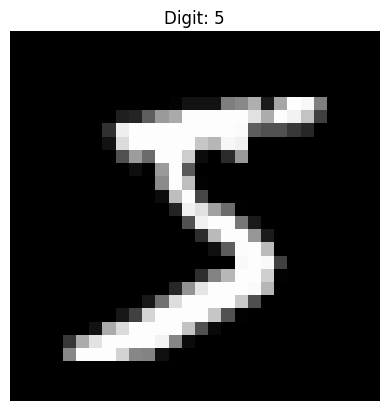

In [18]:
plt.imshow(x_train[0],cmap='gray')
plt.title("Digit: "+str(y_train[0]))
plt.axis('off')
plt.show()

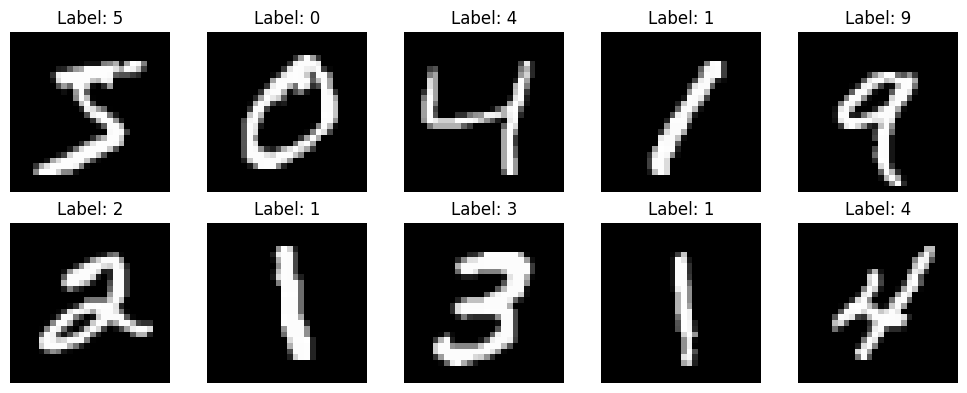

In [19]:
plt.figure(figsize=(10,4))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Label: " + str(y_train[i]))
    plt.axis('off')
plt.tight_layout()
plt.show()
    

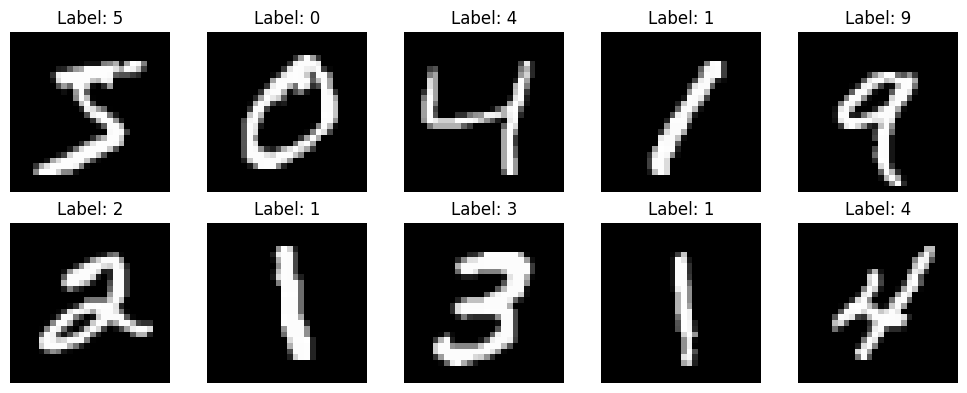

In [20]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Label: " + str(y_train[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [21]:
model=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation='relu'),
    Dense(64,activation='relu'),
    Dense(10,activation='softmax')

])

In [22]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
   
    metrics=['accuracy']
)

In [24]:
x_train = x_train.astype('float32')/255.0
x_test=x_test.astype('float32')/255.0




In [25]:
history=model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6741 - loss: 1.2969 - val_accuracy: 0.8693 - val_loss: 0.5969
Epoch 2/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8600 - loss: 0.5400 - val_accuracy: 0.9065 - val_loss: 0.3759
Epoch 3/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8859 - loss: 0.4122 - val_accuracy: 0.9193 - val_loss: 0.3107
Epoch 4/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9000 - loss: 0.3580 - val_accuracy: 0.9242 - val_loss: 0.2757
Epoch 5/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9090 - loss: 0.3258 - val_accuracy: 0.9302 - val_loss: 0.2546
Epoch 6/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9150 - loss: 0.3028 - val_accuracy: 0.9330 - val_loss: 0.2401
Epoch 7/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9203 - loss: 0.2855 - val_accuracy: 0.9360 - val_loss: 0.2277
Epoch 8/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9243 - loss: 0.2710 - val_accuracy: 0.

In [26]:
test_loss,test_accuracy=model.evaluate(

    x_test,
    y_test
)

print("Test loss:",test_loss)
print("Test Accuracy:",test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9370 - loss: 0.2254
Test loss: 0.22542054951190948
Test Accuracy: 0.9369999766349792


In [27]:
print("Training labels:", y_train[:10])
print("Testing labels:", y_test[:10])

Training labels: [5 0 4 1 9 2 1 3 1 4]
Testing labels: [7 2 1 0 4 1 4 9 5 9]


In [28]:
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [29]:
print("Training accuracy:", history.history['accuracy'])
print("Validation accuracy:", history.history['val_accuracy'])
print("Training loss:", history.history['loss'])

Training accuracy: [0.6740555763244629, 0.8599629402160645, 0.8859259486198425, 0.8999999761581421, 0.9089815020561218, 0.9150000214576721, 0.9202592372894287, 0.9243147969245911, 0.9272592663764954, 0.9298333525657654, 0.9326111078262329]
Validation accuracy: [0.8693333268165588, 0.906499981880188, 0.9193333387374878, 0.9241666793823242, 0.9301666617393494, 0.9330000281333923, 0.9359999895095825, 0.940500020980835, 0.9431666731834412, 0.9441666603088379, 0.9473333358764648]
Training loss: [1.29691743850708, 0.5400102138519287, 0.41221946477890015, 0.35801705718040466, 0.32576295733451843, 0.3028179705142975, 0.28553274273872375, 0.2709929347038269, 0.25866928696632385, 0.2481289803981781, 0.2383837103843689]


In [30]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [31]:
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [32]:
history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.6751 - loss: 1.2927 - val_accuracy: 0.8712 - val_loss: 0.6145
Epoch 2/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8636 - loss: 0.5393 - val_accuracy: 0.9040 - val_loss: 0.3842
Epoch 3/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8867 - loss: 0.4128 - val_accuracy: 0.9148 - val_loss: 0.3183
Epoch 4/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8986 - loss: 0.3622 - val_accuracy: 0.9230 - val_loss: 0.2851
Epoch 5/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9062 - loss: 0.3324 - val_accuracy: 0.9277 - val_loss: 0.2622
Epoch 6/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9118 - loss: 0.3112 - val_accuracy: 0.9317 - val_loss: 0.2469
Epoch 7/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9162 - loss: 0.2943 - val_accuracy: 0.9343 - val_loss: 0.2336
Epoch 8/11
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9201 - loss: 0.2802 - val_accuracy: 0

In [33]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9350 - loss: 0.2328
Test Loss: 0.23281756043434143
Test Accuracy: 0.9350000023841858


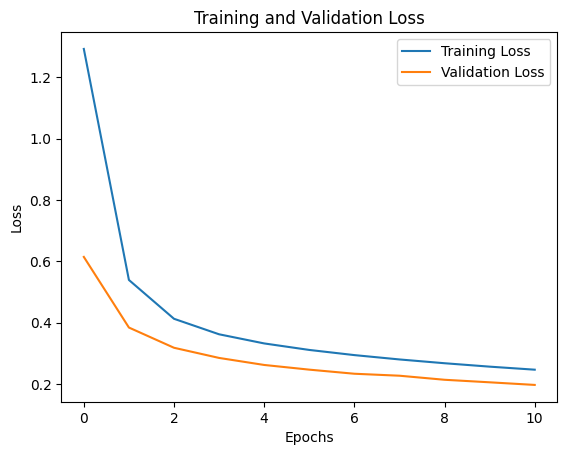

In [35]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

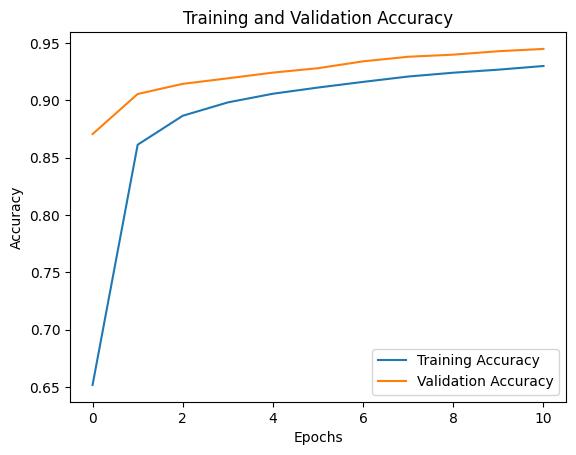

In [71]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()